# 03 — Huấn luyện và so sánh mô hình

Chỉ dùng train của giai đoạn 2, tách validation cố định 20%. So sánh tại ngưỡng 0.5; chọn cấu hình theo AP trên validation. Không đọc dữ liệu test.

## 1. Thư viện và đường dẫn

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_recall_curve, precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

In [2]:
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CANDIDATES_DIR = PROJECT_ROOT / "models" / "candidates"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
for folder in [CANDIDATES_DIR, REPORTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.max_columns", 20)

## 2. Đọc train chưa chuẩn hóa

In [3]:
input_paths = [PROCESSED_DIR / "X_train_raw.csv", PROCESSED_DIR / "y_train.csv"]
for path in input_paths:
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu {path}; hãy chạy notebook 02 trước.")

X_train_raw = pd.read_csv(input_paths[0], float_precision="round_trip")
y_train = pd.read_csv(input_paths[1])["Class"]
print("X_train_raw:", X_train_raw.shape)
print("y_train:", y_train.shape)

X_train_raw: (226980, 30)
y_train: (226980,)


In [4]:
feature_columns = X_train_raw.columns.tolist()
scale_columns = ["Time", "Amount"]
v_columns = [f"V{i}" for i in range(1, 29)]
assert feature_columns == ["Time", *v_columns, "Amount"]
assert X_train_raw.index.equals(y_train.index)
assert X_train_raw.notna().all().all() and y_train.notna().all()
assert np.isfinite(X_train_raw.to_numpy()).all()
assert set(y_train.unique()) == {0, 1}
assert not X_train_raw.duplicated().any()

display(pd.DataFrame({"Đặc trưng": feature_columns}))
display(y_train.value_counts().sort_index().rename("Số lượng").to_frame())

,Đặc trưng
0,Time
1,V1
2,V2
3,V3
4,V4
5,V5
6,V6
7,V7
8,V8
9,V9


,Số lượng
Class,
0,226602
1,378


## 3. Chia training và validation

In [5]:
X_training, X_validation, y_training, y_validation = train_test_split(
    X_train_raw, y_train, test_size=0.2, stratify=y_train, random_state=42,
)
assert X_training.index.intersection(X_validation.index).empty
assert X_training.index.equals(y_training.index)
assert X_validation.index.equals(y_validation.index)
assert len(X_training) + len(X_validation) == len(X_train_raw)

split_shapes = pd.DataFrame({
    "X": [X_training.shape, X_validation.shape],
    "y": [y_training.shape, y_validation.shape],
}, index=["Training", "Validation"])
display(split_shapes)

,X,y
Training,"(181584, 30)","(181584,)"
Validation,"(45396, 30)","(45396,)"


In [6]:
label_counts = pd.DataFrame({
    "Train giai đoạn 2": y_train.value_counts(),
    "Training": y_training.value_counts(),
    "Validation": y_validation.value_counts(),
}).reindex([0, 1], fill_value=0)
label_counts.index.name = "Class"
assert (label_counts["Training"] + label_counts["Validation"]).equals(label_counts["Train giai đoạn 2"])
display(label_counts)
display((label_counts.div(label_counts.sum(), axis="columns") * 100).round(4))

,Train giai đoạn 2,Training,Validation
Class,,,
0,226602,181282,45320
1,378,302,76


,Train giai đoạn 2,Training,Validation
Class,,,
0,99.8335,99.8337,99.8326
1,0.1665,0.1663,0.1674


## 4. Huấn luyện và đánh giá trên validation

Dùng chung một hàm ngắn để giữ cách đo thời gian và tính chỉ số nhất quán. AP là Average Precision, không phải diện tích hình thang của đường PR. Precision/Recall/F1 dùng ngưỡng 0.5; không dùng accuracy để xếp hạng.

In [7]:
results = []
fitted_models = {}
validation_probabilities = {}
warning_records = []
threshold = 0.5

In [8]:
def train_candidate(candidate_id, model_name, model):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        start = perf_counter()
        model.fit(X_training, y_training)
        fit_seconds = perf_counter() - start
    start = perf_counter()
    probabilities = model.predict_proba(X_validation)[:, 1]
    predict_seconds = perf_counter() - start
    assert model.classes_.tolist() == [0, 1]
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_validation, predictions, labels=[0, 1]).ravel()
    estimator = model.named_steps["classifier"] if isinstance(model, Pipeline) else model
    parameter_names = ["C", "max_iter", "class_weight", "n_estimators", "max_depth", "min_samples_leaf", "learning_rate", "scale_pos_weight", "eval_metric", "random_state", "n_jobs"]
    parameters = {name: value for name, value in estimator.get_params().items() if name in parameter_names}
    results.append({
        "candidate_id": candidate_id, "model": model_name,
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1": f1_score(y_validation, predictions, zero_division=0),
        "AP": average_precision_score(y_validation, probabilities),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
        "threshold": threshold, "warning_count": len(caught),
        "parameters": json.dumps(parameters, ensure_ascii=False, sort_keys=True),
    })
    fitted_models[candidate_id] = model
    validation_probabilities[candidate_id] = probabilities
    for warning in caught:
        record = {"candidate_id": candidate_id, "category": warning.category.__name__, "message": str(warning.message)}
        warning_records.append(record)
        print(f"Cảnh báo {candidate_id}: {record['category']}: {record['message']}")
    print(f"{candidate_id}: fit {fit_seconds:.2f}s; dự đoán {predict_seconds:.2f}s; {len(caught)} cảnh báo khi fit.")

### Logistic Regression

Pipeline nhận DataFrame thô với 30 cột theo thứ tự ban đầu. StandardScaler chỉ học Time và Amount từ training; V1–V28 đi qua nguyên giá trị.

In [9]:
preprocessor = ColumnTransformer(
    [("scale", StandardScaler(), scale_columns)],
    remainder="passthrough", verbose_feature_names_out=False,
).set_output(transform="pandas")
lr_baseline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        C=1.0, class_weight="balanced", max_iter=1000, random_state=42,
    )),
])
train_candidate("lr_c1", "Logistic Regression", lr_baseline)

Cảnh báo lr_c1: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
lr_c1: fit 1.44s; dự đoán 0.04s; 1 cảnh báo khi fit.


### Random Forest

In [10]:
rf_baseline = RandomForestClassifier(
    n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1,
)
train_candidate("rf_leaf1", "Random Forest", rf_baseline)

rf_leaf1: fit 17.67s; dự đoán 0.08s; 0 cảnh báo khi fit.


### XGBoost

In [11]:
training_counts = y_training.value_counts()
scale_pos_weight = float(training_counts.loc[0] / training_counts.loc[1])
print(f"scale_pos_weight từ training: {scale_pos_weight:.4f}")
xgb_baseline = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    scale_pos_weight=scale_pos_weight, eval_metric="logloss",
    random_state=42, n_jobs=-1,
)
train_candidate("xgb_depth4", "XGBoost", xgb_baseline)

scale_pos_weight từ training: 600.2715
xgb_depth4: fit 2.36s; dự đoán 0.02s; 0 cảnh báo khi fit.


### So sánh cấu hình ban đầu

In [12]:
baseline_ids = ["lr_c1", "rf_leaf1", "xgb_depth4"]
metric_columns = ["Precision", "Recall", "F1", "AP", "fit_seconds"]
baseline_results = pd.DataFrame(results)
display(baseline_results[["candidate_id", "model", *metric_columns]].round(4))

,candidate_id,model,Precision,Recall,F1,AP,fit_seconds
0,lr_c1,Logistic Regression,0.0544,0.8947,0.1025,0.8137,1.4437
1,rf_leaf1,Random Forest,0.9677,0.7895,0.8696,0.8759,17.6687
2,xgb_depth4,XGBoost,0.4820,0.8816,0.6233,0.8616,2.3583


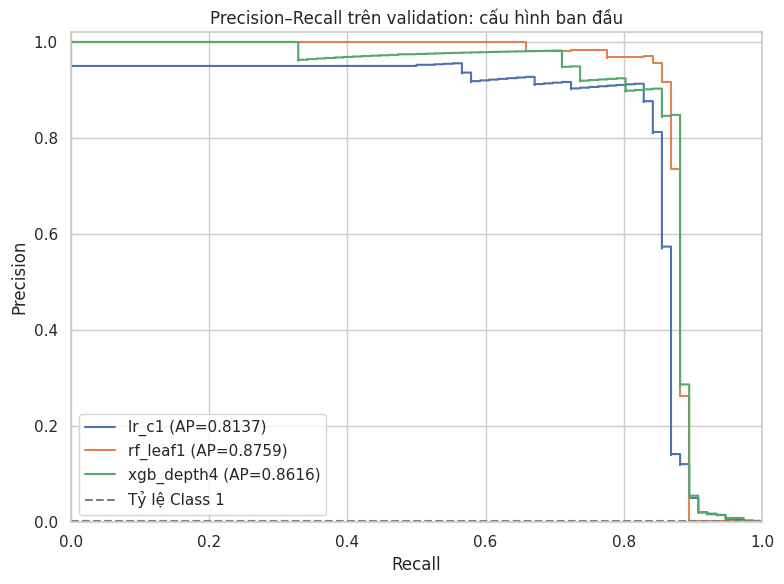

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
for candidate_id in baseline_ids:
    probabilities = validation_probabilities[candidate_id]
    precision, recall, _ = precision_recall_curve(y_validation, probabilities)
    ap = average_precision_score(y_validation, probabilities)
    ax.step(recall, precision, where="post", label=f"{candidate_id} (AP={ap:.4f})")
ax.axhline(y_validation.mean(), color="gray", linestyle="--", label="Tỷ lệ Class 1")
ax.set(title="Precision–Recall trên validation: cấu hình ban đầu", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_baseline_precision_recall.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Thử thêm một cấu hình cho mỗi mô hình

Giữ nguyên training/validation và ngưỡng 0.5. Chỉ đổi C của Logistic Regression, min_samples_leaf của Random Forest và max_depth của XGBoost; không dùng SMOTE.

In [14]:
lr_trial = clone(lr_baseline).set_params(classifier__C=0.1)
train_candidate("lr_c01", "Logistic Regression", lr_trial)

Cảnh báo lr_c01: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
lr_c01: fit 1.22s; dự đoán 0.03s; 1 cảnh báo khi fit.


In [15]:
rf_trial = clone(rf_baseline).set_params(min_samples_leaf=2)
train_candidate("rf_leaf2", "Random Forest", rf_trial)

rf_leaf2: fit 15.95s; dự đoán 0.08s; 0 cảnh báo khi fit.


In [16]:
xgb_trial = clone(xgb_baseline).set_params(max_depth=3)
train_candidate("xgb_depth3", "XGBoost", xgb_trial)

xgb_depth3: fit 1.74s; dự đoán 0.02s; 0 cảnh báo khi fit.


## 6. Tổng hợp và lựa chọn cấu hình

Ưu tiên AP chưa làm tròn; nếu bằng nhau xét F1, Recall, Precision. Đây là kết quả lựa chọn trên validation, chưa phải đánh giá độc lập trên test. Không refit trên toàn bộ train giai đoạn 2 trong notebook này.

In [17]:
validation_results = pd.DataFrame(results).sort_values(
    ["AP", "F1", "Recall", "Precision", "candidate_id"],
    ascending=[False, False, False, False, True],
).reset_index(drop=True)
display(validation_results[["candidate_id", "model", *metric_columns, "TN", "FP", "FN", "TP", "warning_count"]].round(4))
display(validation_results[["candidate_id", "parameters"]])

best_by_model = validation_results.drop_duplicates("model").copy()
best_row = validation_results.iloc[0]
best_candidate_id = best_row["candidate_id"]
print(f"Chọn {best_candidate_id}: AP validation cao nhất = {best_row['AP']:.4f}.")
print(f"Tại ngưỡng 0.5: Precision={best_row['Precision']:.4f}, Recall={best_row['Recall']:.4f}, F1={best_row['F1']:.4f}.")

,candidate_id,model,Precision,Recall,F1,AP,fit_seconds,TN,FP,FN,TP,warning_count
0,rf_leaf2,Random Forest,0.9545,0.8289,0.8873,0.8778,15.9547,45317,3,13,63,0
1,rf_leaf1,Random Forest,0.9677,0.7895,0.8696,0.8759,17.6687,45318,2,16,60,0
2,xgb_depth4,XGBoost,0.4820,0.8816,0.6233,0.8616,2.3583,45248,72,9,67,0
3,lr_c1,Logistic Regression,0.0544,0.8947,0.1025,0.8137,1.4437,44137,1183,8,68,1
4,lr_c01,Logistic Regression,0.0544,0.8947,0.1026,0.8097,1.2169,44139,1181,8,68,1
5,xgb_depth3,XGBoost,0.2179,0.8947,0.3505,0.7993,1.7388,45076,244,8,68,0


,candidate_id,parameters
0,rf_leaf2,"{""class_weight"": ""balanced"", ""max_depth"": null..."
1,rf_leaf1,"{""class_weight"": ""balanced"", ""max_depth"": null..."
2,xgb_depth4,"{""eval_metric"": ""logloss"", ""learning_rate"": 0...."
3,lr_c1,"{""C"": 1.0, ""class_weight"": ""balanced"", ""max_it..."
4,lr_c01,"{""C"": 0.1, ""class_weight"": ""balanced"", ""max_it..."
5,xgb_depth3,"{""eval_metric"": ""logloss"", ""learning_rate"": 0...."


Chọn rf_leaf2: AP validation cao nhất = 0.8778.
Tại ngưỡng 0.5: Precision=0.9545, Recall=0.8289, F1=0.8873.


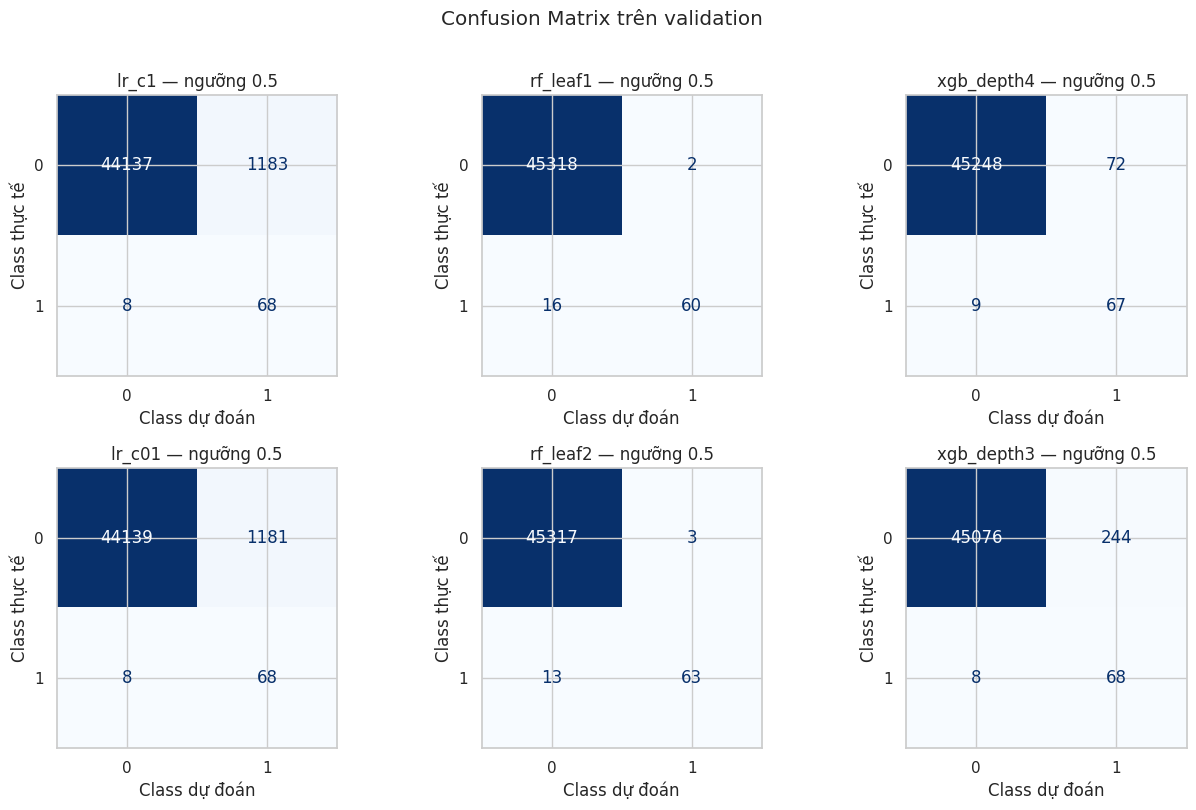

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for candidate_id, ax in zip(fitted_models, axes.flat):
    predictions = (validation_probabilities[candidate_id] >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_validation, predictions, labels=[0, 1], display_labels=[0, 1],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set(title=f"{candidate_id} — ngưỡng 0.5", xlabel="Class dự đoán", ylabel="Class thực tế")
fig.suptitle("Confusion Matrix trên validation", y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_validation_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

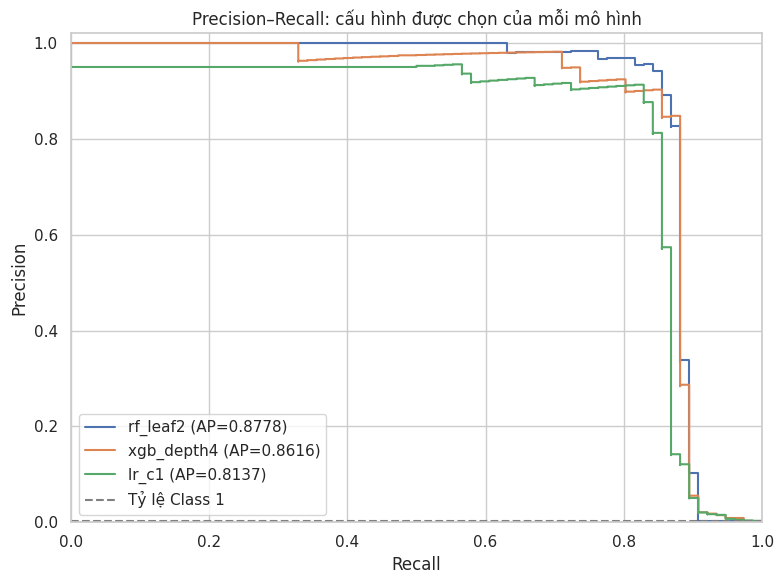

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))
for candidate_id in best_by_model["candidate_id"]:
    probabilities = validation_probabilities[candidate_id]
    precision, recall, _ = precision_recall_curve(y_validation, probabilities)
    ap = average_precision_score(y_validation, probabilities)
    ax.step(recall, precision, where="post", label=f"{candidate_id} (AP={ap:.4f})")
ax.axhline(y_validation.mean(), color="gray", linestyle="--", label="Tỷ lệ Class 1")
ax.set(title="Precision–Recall: cấu hình được chọn của mỗi mô hình", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_selected_precision_recall.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Kiểm tra tiền xử lý và đầu vào mô hình

In [20]:
for candidate_id, model in fitted_models.items():
    assert model.feature_names_in_.tolist() == feature_columns
    if isinstance(model, Pipeline):
        preprocessing = model.named_steps["preprocessing"]
        fitted_scaler = preprocessing.named_transformers_["scale"]
        assert fitted_scaler.n_samples_seen_ == len(X_training)
        np.testing.assert_allclose(fitted_scaler.mean_, X_training[scale_columns].mean(), rtol=1e-12)
        transformed = preprocessing.transform(X_validation)
        pd.testing.assert_frame_equal(transformed[v_columns], X_validation[v_columns])

assert scale_pos_weight == y_training.eq(0).sum() / y_training.eq(1).sum()
assert len(validation_results) == 6
assert len({len(values) for values in validation_probabilities.values()}) == 1
print("Đạt: cùng training/validation, đầu vào thô 30 cột; scaler và trọng số lớp chỉ học từ training.")

Đạt: cùng training/validation, đầu vào thô 30 cột; scaler và trọng số lớp chỉ học từ training.


## 8. Lưu candidates và kết quả validation

Logistic Regression được lưu cả Pipeline; Random Forest/XGBoost nhận trực tiếp 30 đặc trưng thô. Không dùng scaler của giai đoạn 2 cho các candidates này. Không tạo hoặc ghi đè `models/best_model.joblib`.

In [21]:
model_paths = {}
for candidate_id, model in fitted_models.items():
    model_path = CANDIDATES_DIR / f"{candidate_id}.joblib"
    joblib.dump(model, model_path, compress=3)
    model_paths[candidate_id] = str(model_path.relative_to(PROJECT_ROOT))

validation_results.to_csv(REPORTS_DIR / "validation_results.csv", index=False)
baseline_results.to_csv(REPORTS_DIR / "baseline_validation_results.csv", index=False)
best_by_model.to_csv(REPORTS_DIR / "best_validation_by_model.csv", index=False)

In [22]:
validation_predictions = pd.DataFrame({
    "row_index_in_stage2_train": X_validation.index,
    "Class": y_validation.to_numpy(),
    **validation_probabilities,
})
validation_predictions.to_csv(REPORTS_DIR / "validation_predictions.csv", index=False)
np.savez_compressed(
    REPORTS_DIR / "training_validation_indices.npz",
    training_indices=X_training.index.to_numpy(),
    validation_indices=X_validation.index.to_numpy(),
)
warning_table = pd.DataFrame(warning_records, columns=["candidate_id", "category", "message"])
warning_table.to_csv(REPORTS_DIR / "training_warnings.csv", index=False)
display(warning_table)

,candidate_id,category,message
0,lr_c1,DeprecationWarning,scipy.optimize: The `disp` and `iprint` option...
1,lr_c01,DeprecationWarning,scipy.optimize: The `disp` and `iprint` option...


In [23]:
source_hashes = {}
for path in input_paths:
    with path.open("rb") as file:
        source_hashes[str(path.relative_to(PROJECT_ROOT))] = hashlib.file_digest(file, "sha256").hexdigest()

metadata = {
    "selected_candidate_id": best_candidate_id,
    "selected_model_path": model_paths[best_candidate_id],
    "selection_rule": "validation AP descending, then F1, Recall, Precision; candidate_id breaks remaining ties",
    "threshold": threshold,
    "input_format": "raw pandas DataFrame; columns in feature_columns order",
    "feature_columns": feature_columns,
    "scale_columns_for_logistic_regression": scale_columns,
    "fit_scope": "training subset only; not refitted on all stage2 train",
    "validation_size": 0.2,
    "random_state": 42,
    "training_rows": len(X_training),
    "validation_rows": len(X_validation),
    "class_counts": {name: {str(label): int(count) for label, count in counts.items()} for name, counts in label_counts.to_dict().items()},
    "scale_pos_weight_from_training": scale_pos_weight,
    "test_used": False,
    "source_sha256": source_hashes,
    "split_indices_path": "reports/training_validation_indices.npz",
    "validation_results_path": "reports/validation_results.csv",
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "joblib": joblib.__version__},
    "candidates": [{"candidate_id": row["candidate_id"], "model": row["model"], "path": model_paths[row["candidate_id"]], "parameters": json.loads(row["parameters"]), "metrics": {name: float(row[name]) for name in metric_columns}} for row in results],
    "warnings": warning_records,
}
metadata_path = REPORTS_DIR / "training_metadata.json"
with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2, allow_nan=False)

## 9. Kiểm tra file đã lưu

In [24]:
for candidate_id, relative_path in model_paths.items():
    path = PROJECT_ROOT / relative_path
    assert path.is_file() and path.stat().st_size > 0
    reloaded_model = joblib.load(path)
    assert reloaded_model.feature_names_in_.tolist() == feature_columns
    reloaded_probabilities = reloaded_model.predict_proba(X_validation)[:, 1]
    np.testing.assert_allclose(reloaded_probabilities, validation_probabilities[candidate_id], rtol=0, atol=1e-12)

saved_results = pd.read_csv(REPORTS_DIR / "validation_results.csv", float_precision="round_trip")
pd.testing.assert_frame_equal(saved_results, validation_results, check_exact=True)
with metadata_path.open(encoding="utf-8") as file:
    saved_metadata = json.load(file)
assert saved_metadata["selected_candidate_id"] == best_candidate_id
assert saved_metadata["test_used"] is False
print("Đạt: đọc lại 6 candidates và kết quả; xác suất validation khớp với mô hình trước khi lưu.")
display(best_by_model[["candidate_id", "model", *metric_columns]].round(4))

Đạt: đọc lại 6 candidates và kết quả; xác suất validation khớp với mô hình trước khi lưu.


,candidate_id,model,Precision,Recall,F1,AP,fit_seconds
0,rf_leaf2,Random Forest,0.9545,0.8289,0.8873,0.8778,15.9547
2,xgb_depth4,XGBoost,0.4820,0.8816,0.6233,0.8616,2.3583
3,lr_c1,Logistic Regression,0.0544,0.8947,0.1025,0.8137,1.4437


### Kết thúc giai đoạn 3

Kết quả hiện tại dùng để chọn cấu hình trên validation, có thể lạc quan do đã thử tham số. Giữ test độc lập cho giai đoạn 4; chưa kết luận hiệu năng triển khai thực tế.